# 04 — Classical baseline (N2)

**Question.** How far does a model *without* a neural network go? This is the bar every network has to beat (PLAN §4, criterion 1: significantly better than the best classical model).

**Approach.**
- Hand-crafted features computed from the raw 128 px images:
  - **HSV colour histogram** (12 hue × 4 saturation × 4 value bins = 192 values): the palette of the painting.
  - **HOG** on the 64 px grayscale image (1,764 values): the direction of edges and strokes.
  - **Raw 32 px pixels** (3,072 values): a *control*, to show what the features add over the pixels themselves.
- Three scikit-learn classifiers: logistic regression, linear SVM, RBF SVM, with `C` tuned on the **validation** set.
- One candidate is frozen at the end; the test set is not touched here (it is scored once, in `07_comparison`).

In [1]:
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch  # imported before scikit-learn: see tests/conftest.py
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Unknown solver options")  # scipy/scikit-learn version noise

FAST_RUN = os.environ.get("FAST_RUN") == "1"
FIG, CKPT = "../results/figures", "../checkpoints"
os.makedirs(CKPT, exist_ok=True)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True, "lines.linewidth": 2,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})
print("FAST_RUN =", FAST_RUN)

FAST_RUN = False


In [2]:
import pickle
import sys

sys.path.insert(0, "../src")
from museum.classical import FEATURES, count_learned_values, make_pipeline
from museum.data import CLASSES, get_arrays
from museum.evaluation import benchmark_latency, model_size_mb, plot_confusion, save_result

X_train, y_train = get_arrays(128, "train")
X_val, y_val = get_arrays(128, "val")
assert X_train.shape == (1050, 128, 128, 3) and X_val.shape == (225, 128, 128, 3)
assert np.bincount(y_train).tolist() == [210] * 5 and np.bincount(y_val).tolist() == [45] * 5
print(X_train.shape, X_val.shape, CLASSES)

(1050, 128, 128, 3) (225, 128, 128, 3) ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']


## 1. What the features see

For one painting per style: the image, its HOG (dominant edge direction in each 8×8 cell of the 64 px grayscale image) and its hue histogram (summed over saturation and value).

Caveat when reading the hue row: for nearly grey pixels (low saturation, e.g. the black-and-white Cubist print) the hue is close to arbitrary. The joint HSV histogram used by the model separates those pixels through its saturation bins, so they do not get mixed with truly coloured ones.

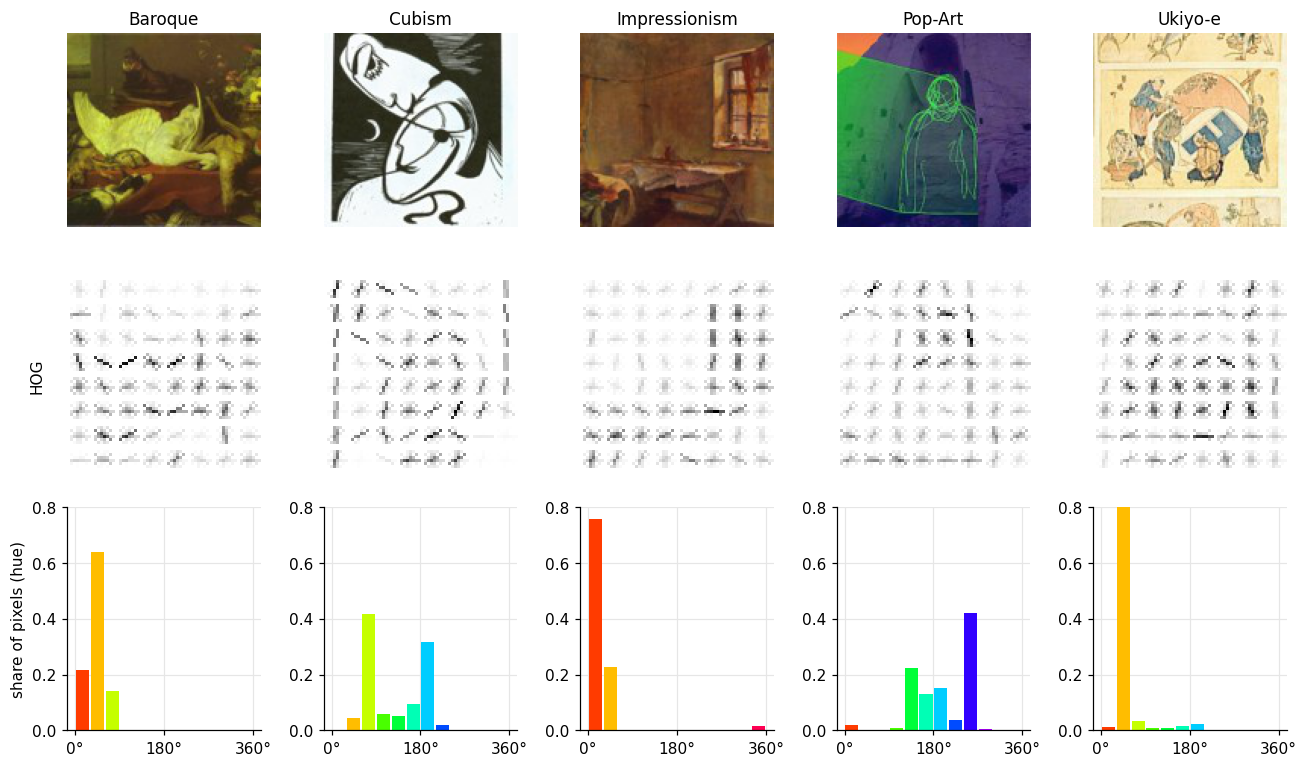

In [3]:
from PIL import Image
from skimage.color import rgb2hsv
from skimage.feature import hog

fig, axes = plt.subplots(3, 5, figsize=(12, 7.2))
for j, c in enumerate(CLASSES):
    img = X_train[np.flatnonzero(y_train == j)[3]]
    gray = np.asarray(Image.fromarray(img).convert("L").resize((64, 64), Image.Resampling.BILINEAR))
    _, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    hue = rgb2hsv(img)[..., 0].ravel()
    axes[0, j].imshow(img)
    axes[0, j].set_title(c.replace("_", "-"))
    axes[1, j].imshow(hog_img, cmap="gray_r")
    counts, edges = np.histogram(hue, bins=12, range=(0, 1))
    centres = (edges[:-1] + edges[1:]) / 2
    axes[2, j].bar(centres, counts / counts.sum(), width=1 / 12 - 0.01,
                   color=[plt.cm.hsv(h) for h in centres], edgecolor="none")
    axes[2, j].set_ylim(0, 0.8)
    axes[2, j].set_xticks([0, 0.5, 1], ["0°", "180°", "360°"])
    for ax in axes[:2, j]:
        ax.axis("off")
axes[1, 0].text(-8, 32, "HOG", rotation=90, va="center", ha="right")
axes[2, 0].set_ylabel("share of pixels (hue)")
fig.tight_layout()
fig.savefig(f"{FIG}/classical_features.png", bbox_inches="tight")
plt.show()

## 2. Features, computed once per split

The scaler and classifier are tuned on these cached arrays; the final pipeline recomputes them from raw images (checked below to give the same validation accuracy).

In [4]:
feats, extract_ms = {}, {}
for name, fn in FEATURES.items():
    start = time.perf_counter()
    feats[name] = (fn(X_train), fn(X_val))
    extract_ms[name] = (time.perf_counter() - start) * 1000 / (len(X_train) + len(X_val))
    print(f"{name:8s} {feats[name][0].shape[1]:5d} features, {extract_ms[name]:.2f} ms per image (batch)")

hsv        192 features, 1.62 ms per image (batch)


hog       1764 features, 0.53 ms per image (batch)


hsv+hog   1956 features, 2.14 ms per image (batch)
raw32     3072 features, 0.06 ms per image (batch)


## 3. Tuning on validation

Every (features, classifier, C) combination is fitted on the 1,050 training images and scored on the 225 validation images. Standardisation is fitted on the training images only.

In [5]:
# The linear SVM gets its own grid, shifted to stronger regularisation: above C = 1 liblinear needs
# minutes to converge on these features and its validation accuracy is already falling (overfitting).
# Each grid is wide enough that the best C is not on its edge (checked below).
C_GRIDS = {"logreg": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
           "linear_svm": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1.0],
           "rbf_svm": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]}
if FAST_RUN:
    C_GRIDS = {k: [v[2]] for k, v in C_GRIDS.items()}
CLASSIFIERS = {
    "logreg": lambda C: LogisticRegression(C=C, max_iter=5000),
    "linear_svm": lambda C: LinearSVC(C=C, dual="auto", max_iter=2000),
    "rbf_svm": lambda C: SVC(C=C, kernel="rbf", gamma="scale"),
}
rows = []
for feat_name, (F_train, F_val) in feats.items():
    for clf_name, make_clf in CLASSIFIERS.items():
        for C in C_GRIDS[clf_name]:
            model = Pipeline([("scale", StandardScaler()), ("clf", make_clf(C))])
            start = time.perf_counter()
            model.fit(F_train, y_train)
            fit_s = time.perf_counter() - start
            rows.append({"features": feat_name, "classifier": clf_name, "C": C,
                         "val_acc": float((model.predict(F_val) == y_val).mean()), "fit_s": fit_s})
grid = pd.DataFrame(rows)
best = grid.loc[grid.groupby(["features", "classifier"])["val_acc"].idxmax()]
best = best.assign(C_on_edge=[C in (C_GRIDS[k][0], C_GRIDS[k][-1]) and not FAST_RUN
                              for C, k in zip(best.C, best.classifier, strict=True)])
print("best C on the edge of its grid:", best[best.C_on_edge][["features", "classifier", "C"]].values.tolist() or "none")
best.pivot(index="features", columns="classifier", values="val_acc").loc[list(FEATURES)].style.format("{:.3f}")

best C on the edge of its grid: [['hog', 'linear_svm', 1e-05], ['hog', 'logreg', 0.001], ['hsv', 'logreg', 0.001], ['raw32', 'linear_svm', 1e-05], ['raw32', 'logreg', 0.001]]


classifier,linear_svm,logreg,rbf_svm
features,,,
hsv,0.453,0.453,0.520
hog,0.422,0.418,0.427
hsv+hog,0.511,0.507,0.551
raw32,0.360,0.364,0.480


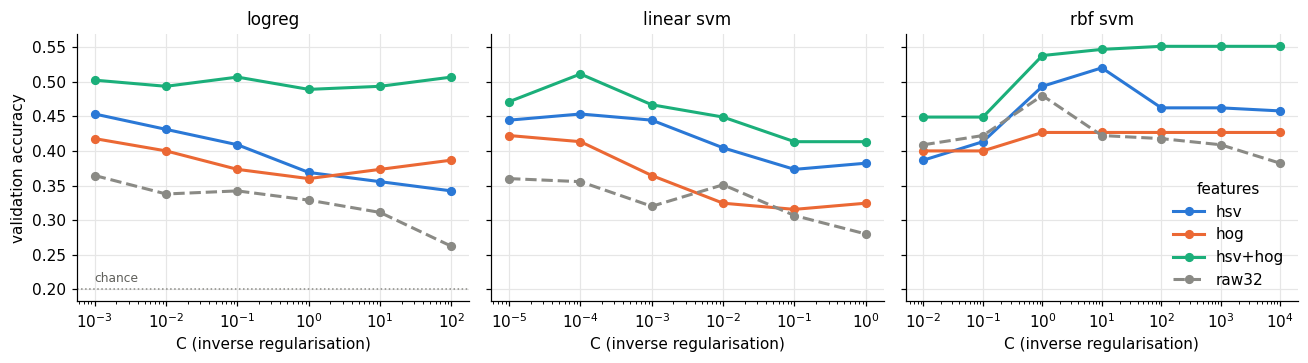

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
colors = {"hsv": "#2a78d6", "hog": "#eb6834", "hsv+hog": "#1baf7a", "raw32": "#8a8a85"}
for ax, clf_name in zip(axes, CLASSIFIERS, strict=True):
    for feat_name in FEATURES:
        sub = grid[(grid.features == feat_name) & (grid.classifier == clf_name)]
        ax.plot(sub.C, sub.val_acc, marker="o", markersize=5, color=colors[feat_name], label=feat_name,
                linestyle="--" if feat_name == "raw32" else "-")
    ax.set_xscale("log")
    ax.set_title(clf_name.replace("_", " "))
    ax.set_xlabel("C (inverse regularisation)")
axes[0].set_ylabel("validation accuracy")
axes[0].axhline(0.2, color="#8a8a85", linewidth=1, linestyle=":")
axes[0].text(C_GRIDS["logreg"][0], 0.21, "chance", color="#5f5f5a", fontsize=8)
axes[-1].legend(title="features", loc="lower right")
fig.tight_layout()
fig.savefig(f"{FIG}/classical_val_grid.png", bbox_inches="tight")
plt.show()

## 4. Freezing the classical candidate

Rule, fixed before looking at the grid: the best validation accuracy among the real feature sets (`raw32` is only a control). Ties go to the simpler model (logistic regression < linear SVM < RBF SVM), then to the smaller `C` (stronger regularisation).

In [7]:
simplicity = {name: i for i, name in enumerate(CLASSIFIERS)}
candidates = grid[grid.features != "raw32"].assign(simple=lambda d: d.classifier.map(simplicity))
chosen = candidates.sort_values(["val_acc", "simple", "C"], ascending=[False, True, True]).iloc[0]
raw_best = grid[grid.features == "raw32"].val_acc.max()
print(f"chosen: {chosen.features} + {chosen.classifier}, C={chosen.C}, val acc {chosen.val_acc:.3f}")
print(f"raw 32 px control, best: {raw_best:.3f}  -> the features add {chosen.val_acc - raw_best:+.3f}")

chosen: hsv+hog + rbf_svm, C=100.0, val acc 0.551
raw 32 px control, best: 0.480  -> the features add +0.071


In [8]:
pipe = make_pipeline(chosen.features, CLASSIFIERS[chosen.classifier](chosen.C))
start = time.perf_counter()
pipe.fit(X_train, y_train)          # from raw images: feature extraction is part of the training time
train_time_s = time.perf_counter() - start
val_pred = pipe.predict(X_val)
val_acc = float((val_pred == y_val).mean())
assert abs(val_acc - chosen.val_acc) < 1e-9, "the end-to-end pipeline must reproduce the tuned model"
print(f"end-to-end pipeline: val acc {val_acc:.3f}, trained in {train_time_s:.1f} s")
plot_confusion(y_val, val_pred, CLASSES, f"{FIG}/classical_val_confusion.png", title="Classical (validation)")
per_class = pd.Series([(val_pred[y_val == k] == k).mean() for k in range(5)], index=CLASSES, name="val recall")
per_class.to_frame().T.style.format("{:.2f}")

end-to-end pipeline: val acc 0.551, trained in 3.0 s


,Baroque,Cubism,Impressionism,Pop_Art,Ukiyo_e
val recall,0.56,0.51,0.51,0.64,0.53


## 5. Cost: CPU latency, size

Latency is measured end to end on one raw 128 px image (feature extraction + scaler + classifier), batch 1, on CPU, with 1 and 2 threads (10 warm-up + 100 timed runs).

In [9]:
sample = X_val[0]
predict_one = lambda image: pipe.predict(image[None])[0]  # noqa: E731
runs = 20 if FAST_RUN else 100
latency = {f"threads_{t}": benchmark_latency(predict_one, sample, n_threads=t, runs=runs) for t in (1, 2)}
with open(f"{CKPT}/classical.pkl", "wb") as handle:
    pickle.dump(pipe, handle)
size_mb = model_size_mb(f"{CKPT}/classical.pkl")
n_values = count_learned_values(pipe)
print(pd.DataFrame(latency).round(2))
print(f"size {size_mb:.2f} MB, {n_values:,} learned values")

           threads_1  threads_2
median_ms       2.98       2.97
p95_ms          3.11       3.07
size 16.49 MB, 2,058,002 learned values


In [10]:
path = save_result("classical", {
    "config": {"features": chosen.features, "classifier": chosen.classifier, "C": float(chosen.C),
               "hsv_bins": [12, 4, 4], "hog": {"size": 64, "orientations": 9, "cell": 8, "block": 2},
               "raw32_control_val_acc": float(raw_best), "fast_run": FAST_RUN},
    "val_acc": val_acc, "n_params": int(n_values), "size_mb": size_mb,
    "latency_ms": latency, "train_time_s": train_time_s,
})
print("wrote", path.relative_to(path.parents[1]))

wrote results/classical.json


## What we see

- **Colour is the strongest single cue**: the HSV histogram alone beats HOG alone with every classifier.
- **HOG alone is weak** — with the RBF kernel it is not better than the raw 32 px pixels. Texture only helps **in combination** with colour: HSV + HOG is the best feature set for all three classifiers.
- **The non-linear (RBF) SVM wins**: style classes are not linearly separable in this feature space.
- **Grid edges**: the chosen C is inside its grid. The only best values left on an edge are linear models on the weak feature sets (HSV, HOG, raw pixels), which keep gaining a little from stronger regularisation; they are more than 10 points below the candidate, so a wider grid cannot change the choice.
- **The classical candidate is far from the 85 % target** (see the validation accuracy above, with 5 classes chance is 20 %). It is cheap: a few milliseconds per image on one CPU thread (2 threads change nothing for a single small image) and a small pickle. The networks have to beat it **significantly** to be worth their cost.